## **Data Ingestion**

In [0]:
import pandas as pd
import numpy as np

In [0]:
payers = spark. table("analystlab.default.payers").toPandas()

display(payers)

Id,NAME,ADDRESS,CITY,STATE_HEADQUARTERED,ZIP,PHONE
b3221cfc-24fb-339e-823d-bc4136cbc4ed,Dual Eligible,7500 Security Blvd,Baltimore,MD,21244.0,1-877-267-2323
7caa7254-5050-3b5e-9eae-bd5ea30e809c,Medicare,7500 Security Blvd,Baltimore,MD,21244.0,1-800-633-4227
7c4411ce-02f1-39b5-b9ec-dfbea9ad3c1a,Medicaid,7500 Security Blvd,Baltimore,MD,21244.0,1-877-267-2323
d47b3510-2895-3b70-9897-342d681c769d,Humana,500 West Main St,Louisville,KY,40018.0,1-844-330-7799
6e2f1a2d-27bd-3701-8d08-dae202c58632,Blue Cross Blue Shield,Michigan Plaza,Chicago,IL,60007.0,1-800-262-2583
5059a55e-5d6e-34d1-b6cb-d83d16e57bcf,UnitedHealthcare,9800 Healthcare Lane,Minnetonka,MN,55436.0,1-888-545-5205
4d71f845-a6a9-3c39-b242-14d25ef86a8d,Aetna,151 Farmington Ave,Hartford,CT,6156.0,1-800-872-3862
047f6ec3-6215-35eb-9608-f9dda363a44c,Cigna Health,900 Cottage Grove Rd,Bloomfield,CT,6002.0,1-800-997-1654
42c4fca7-f8a9-3cd1-982a-dd9751bf3e2a,Anthem,220 Virginia Ave,Indianapolis,IN,46204.0,1-800-331-1476
b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,NO_INSURANCE,null,null,null,null,null



# 1. Research Question and Objectives

# 1.1 Research Question

How are healthcare payer organisations geographically distributed across cities and states in the available dataset?

### 1.2 Relevance of the Research Question

Healthcare payer organisations play an important role in financing healthcare services. Understanding where these organisations are headquartered provides a basic overview of their geographical representation.

This investigation examines the distribution of payer organisations across different cities and states. It aims to identify locations with higher representation and describe geographical patterns in the available data.

The findings may provide a starting point for understanding the geographical distribution of healthcare payer organisations. However, the analysis does not measure the number of insured patients, insurance coverage or access to healthcare services.

### 1.3 Research Objectives

The objectives of this investigation are:

1. To identify the healthcare payer organisations included in the dataset.
2. To examine the geographical distribution of payer organisations across cities and states.
3. To identify the cities and states with the highest representation.
4. To investigate geographical patterns and differences in payer distribution.
5. To evaluate the limitations of the available dataset and provide recommendations based on the findings.

**Exploratary Data Analyst(EDA)**

In [0]:
 # Task 2 –  Inspect payer dataset

# Display the first five rows
payers.head()

,Id,NAME,ADDRESS,CITY,STATE_HEADQUARTERED,ZIP,PHONE
0,b3221cfc-24fb-339e-823d-bc4136cbc4ed,Dual Eligible,7500 Security Blvd,Baltimore,MD,21244.0,1-877-267-2323
1,7caa7254-5050-3b5e-9eae-bd5ea30e809c,Medicare,7500 Security Blvd,Baltimore,MD,21244.0,1-800-633-4227
2,7c4411ce-02f1-39b5-b9ec-dfbea9ad3c1a,Medicaid,7500 Security Blvd,Baltimore,MD,21244.0,1-877-267-2323
3,d47b3510-2895-3b70-9897-342d681c769d,Humana,500 West Main St,Louisville,KY,40018.0,1-844-330-7799
4,6e2f1a2d-27bd-3701-8d08-dae202c58632,Blue Cross Blue Shield,Michigan Plaza,Chicago,IL,60007.0,1-800-262-2583


In [0]:
 # Check the number of rows and columns
print("Dataset shape:", payers.shape)

Dataset shape: (10, 7)


In [0]:
 # Check column names, data types and missing values
payers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Id                   10 non-null     object 
 1   NAME                 10 non-null     object 
 2   ADDRESS              9 non-null      object 
 3   CITY                 9 non-null      object 
 4   STATE_HEADQUARTERED  9 non-null      object 
 5   ZIP                  9 non-null      float64
 6   PHONE                9 non-null      object 
dtypes: float64(1), object(6)
memory usage: 692.0+ bytes


In [0]:
# Generate descriptive statistics
payers.describe(include="all")

,Id,NAME,ADDRESS,CITY,STATE_HEADQUARTERED,ZIP,PHONE
count,10,10,9,9,9,9.000000,9
unique,10,10,7,7,6,NaN,8
top,b3221cfc-24fb-339e-823d-bc4136cbc4ed,Dual Eligible,7500 Security Blvd,Baltimore,MD,NaN,1-877-267-2323
freq,1,1,3,3,3,NaN,2
mean,NaN,NaN,NaN,NaN,NaN,30839.444444,NaN
std,NaN,NaN,NaN,NaN,NaN,20243.644158,NaN
min,NaN,NaN,NaN,NaN,NaN,6002.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,21244.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,21244.000000,NaN
75%,NaN,NaN,NaN,NaN,NaN,46204.000000,NaN


In [0]:
#Check missing values
print("Missing values per column:")
print(payers.isnull().sum())

Missing values per column:
Id                     0
NAME                   0
ADDRESS                1
CITY                   1
STATE_HEADQUARTERED    1
ZIP                    1
PHONE                  1
dtype: int64


In [0]:
#Check missing values percentage
print("\nMissing values percentage:")
print((payers.isnull().sum() / len(payers)) * 100)


Missing values percentage:
Id                      0.0
NAME                    0.0
ADDRESS                10.0
CITY                   10.0
STATE_HEADQUARTERED    10.0
ZIP                    10.0
PHONE                  10.0
dtype: float64


In [0]:
 # Check duplicate records
print("Duplicate rows:", payers.duplicated().sum())

# Check duplicate payer IDs
print("Duplicate IDs:", payers["Id"].duplicated().sum())

# Check duplicate payer names
print("Duplicate payer names:", payers["NAME"].duplicated().sum())

Duplicate rows: 0
Duplicate IDs: 0
Duplicate payer names: 0


In [0]:
 # Task 2 – Point 2: Correct ZIP data type

payers["ZIP"] = payers["ZIP"].astype("Int64").astype("string")

print(payers[["NAME", "ZIP"]])
print("\nZIP data type:", payers["ZIP"].dtype)

                     NAME    ZIP
0           Dual Eligible  21244
1                Medicare  21244
2                Medicaid  21244
3                  Humana  40018
4  Blue Cross Blue Shield  60007
5        UnitedHealthcare  55436
6                   Aetna   6156
7            Cigna Health   6002
8                  Anthem  46204
9            NO_INSURANCE   <NA>

ZIP data type: string


In [0]:
 # Task 2 – Point 2: Check unique categorical values

print("Payer names:")
print(payers["NAME"].unique())

print("\nCities:")
print(payers["CITY"].unique())

print("\nStates:")
print(payers["STATE_HEADQUARTERED"].unique())

Payer names:
['Dual Eligible' 'Medicare' 'Medicaid' 'Humana' 'Blue Cross Blue Shield'
 'UnitedHealthcare' 'Aetna' 'Cigna Health' 'Anthem' 'NO_INSURANCE']

Cities:
['Baltimore' 'Louisville' 'Chicago' 'Minnetonka' 'Hartford' 'Bloomfield'
 'Indianapolis' None]

States:
['MD' 'KY' 'IL' 'MN' 'CT' 'IN' None]


In [0]:
 # Check for leading or trailing spaces

for column in ["NAME", "ADDRESS", "CITY", "STATE_HEADQUARTERED", "PHONE"]:
    print(column, ":", (payers[column] != payers[column].str.strip()).sum())

NAME : 0
ADDRESS : 1
CITY : 1
STATE_HEADQUARTERED : 1
PHONE : 1


In [0]:
 # Task 2 – Point 2: Check unique categorical values

print("Payer names:")
print(payers["NAME"].unique())

print("\nCities:")
print(payers["CITY"].unique())

print("\nStates:")
print(payers["STATE_HEADQUARTERED"].unique())

Payer names:
['Dual Eligible' 'Medicare' 'Medicaid' 'Humana' 'Blue Cross Blue Shield'
 'UnitedHealthcare' 'Aetna' 'Cigna Health' 'Anthem' 'NO_INSURANCE']

Cities:
['Baltimore' 'Louisville' 'Chicago' 'Minnetonka' 'Hartford' 'Bloomfield'
 'Indianapolis' None]

States:
['MD' 'KY' 'IL' 'MN' 'CT' 'IN' None]


In [0]:
 # Task 2 – Point 2: Verify unnecessary spaces

columns = ["NAME", "ADDRESS", "CITY",
           "STATE_HEADQUARTERED", "PHONE"]

for column in columns:
    spaces = (
        payers[column]
        .dropna()
        .astype(str)
        .ne(payers[column].dropna().astype(str).str.strip())
        .sum()
    )

    print(column, ":", spaces)

NAME : 0
ADDRESS : 0
CITY : 0
STATE_HEADQUARTERED : 0
PHONE : 0


In [0]:
 # Task 2 – Point 3: Count payers by state

print(payers["STATE_HEADQUARTERED"].value_counts())

STATE_HEADQUARTERED
MD    3
CT    2
KY    1
IL    1
MN    1
IN    1
Name: count, dtype: int64


In [0]:
 print(payers["CITY"].value_counts())

CITY
Baltimore       3
Louisville      1
Chicago         1
Minnetonka      1
Hartford        1
Bloomfield      1
Indianapolis    1
Name: count, dtype: int64


Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


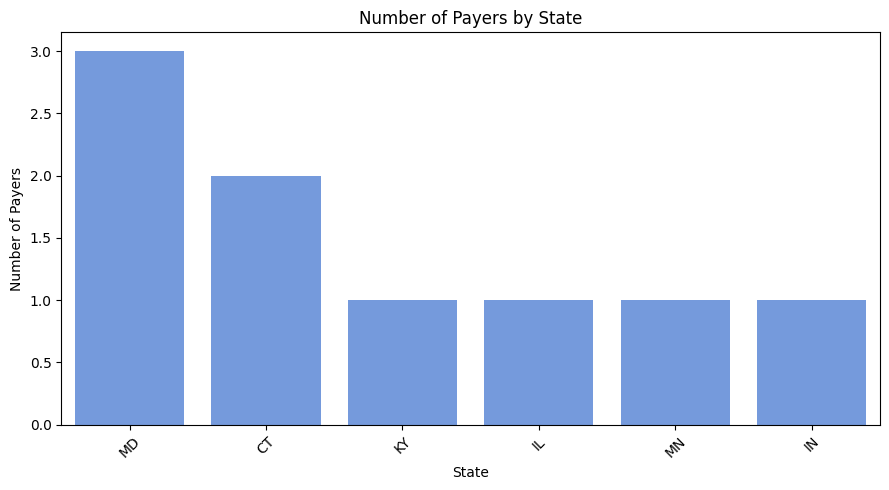

In [0]:
 # Task 2 – Point 4: Payers by state

%pip install seaborn

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.countplot(
    data=payers,
    x="STATE_HEADQUARTERED",
    order=payers["STATE_HEADQUARTERED"].value_counts().index,
    color="cornflowerblue"
)

plt.title("Number of Payers by State")
plt.xlabel("State")
plt.ylabel("Number of Payers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [0]:
 # Task 2 – Point 4: Payers by state

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.countplot(
    data=payer,
    x="STATE_HEADQUARTERED",
    order=payer["STATE_HEADQUARTERED"].value_counts().index,
    color="cornflowerblue"
)

plt.title("Number of Payers by State")
plt.xlabel("State")
plt.ylabel("Number of Payers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<Figure size 900x500 with 0 Axes>

---------------------------------------------------------------------------
NameError                                 Traceback (most recent call last)
File <command-6237385084344188>, line 9
      4 import seaborn as sns
      6 plt.figure(figsize=(9, 5))
      8 sns.countplot(
----> 9     data=payer,
     10     x="STATE_HEADQUARTERED",
     11     order=payer["STATE_HEADQUARTERED"].value_counts().index,
     12     color="cornflowerblue"
     13 )
     15 plt.title("Number of Payers by State")
     16 plt.xlabel("State")

NameError: name 'payer' is not defined

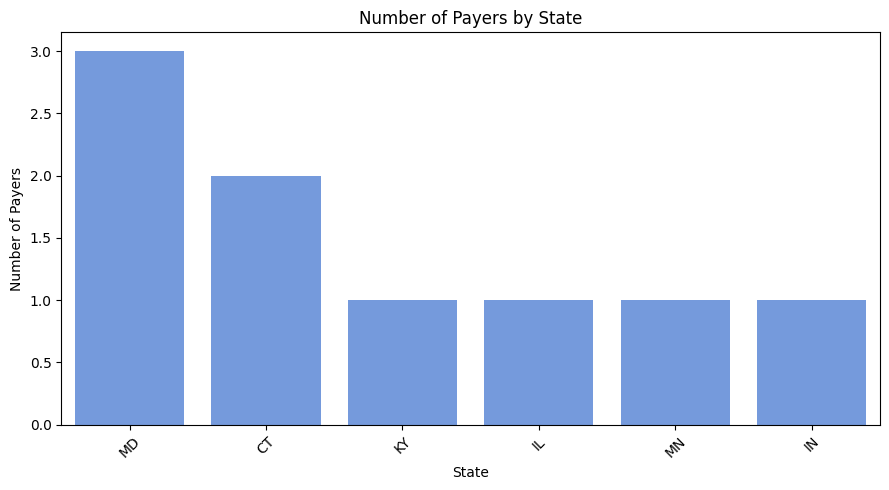

In [0]:
 # Task 2 – Point 4: Payers by state

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.countplot(
    data=payers,
    x="STATE_HEADQUARTERED",
    order=payers["STATE_HEADQUARTERED"].value_counts().index,
    color="cornflowerblue"
)

plt.title("Number of Payers by State")
plt.xlabel("State")
plt.ylabel("Number of Payers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

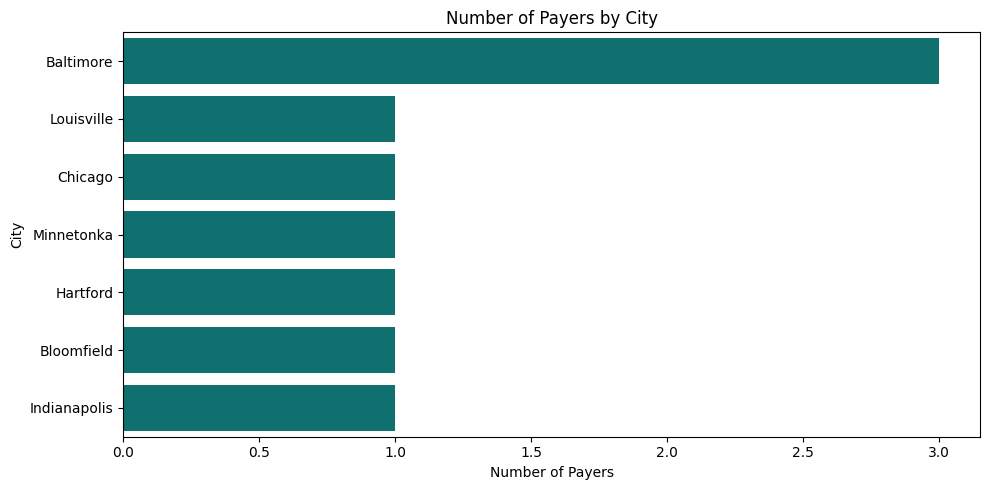

In [0]:
 # Task 2 – Point 4: Payers by city

plt.figure(figsize=(10, 5))

sns.countplot(
    data=payers,
    y="CITY",
    order=payers["CITY"].value_counts().index,
    color="teal"
)

plt.title("Number of Payers by City")
plt.xlabel("Number of Payers")
plt.ylabel("City")
plt.tight_layout()
plt.show()

The bar chart shows that Baltimore has the highest number of payer records, with three records. The remaining six cities each have one record. This indicates that Baltimore is the most represented city in the dataset. However, the small dataset size limits the ability to generalise these finding

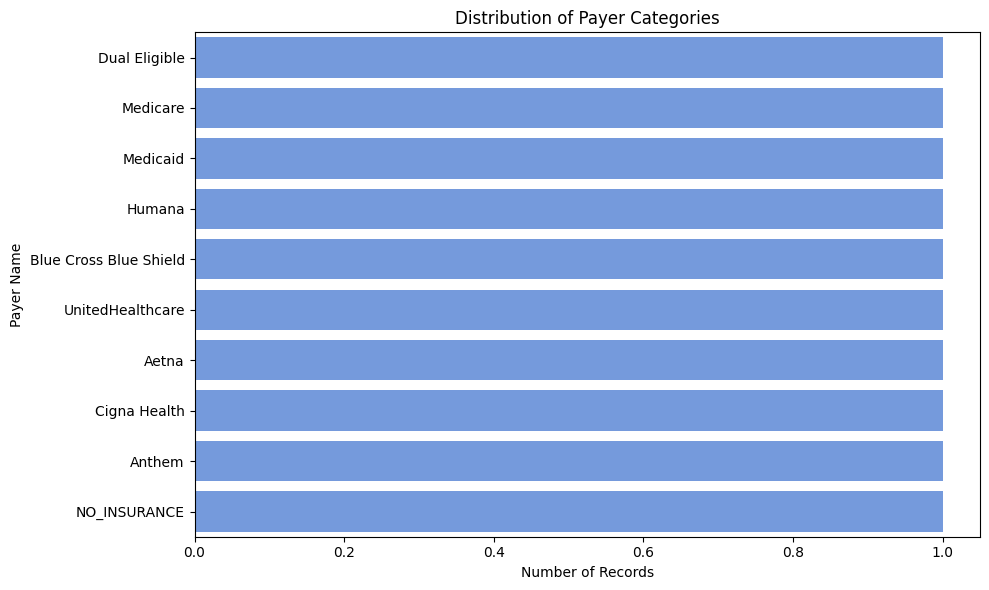

In [0]:
 # Task 2 – Point 4: Payer distribution by name

plt.figure(figsize=(10, 6))

sns.countplot(
    data=payers,
    y="NAME",
    order=payers["NAME"].value_counts().index,
    color="cornflowerblue"
)

plt.title("Distribution of Payer Categories")
plt.xlabel("Number of Records")
plt.ylabel("Payer Name")
plt.tight_layout()
plt.show()

The exploratory data analysis of the payer dataset identified 10 unique payer records representing different healthcare insurance providers and payer categories. The analysis found no duplicate records, IDs or payer names. Missing information was identified in the NO_INSURANCE record, while Baltimore and Maryland had the highest geographical representation. Three visualisations were created to examine payer distribution by state, city and category. However, the small dataset size and absence of patient, claims and financial information limit the conclusions that can be drawn. The findings describe the available payer records but cannot establish insurance popularity, usage or financial performance.

In [0]:
 # Task 3 – Hypothesis 1: Payer distribution by state

state_counts = payers["STATE_HEADQUARTERED"].value_counts()

state_percentages = (
    payers["STATE_HEADQUARTERED"]
    .value_counts(normalize=True) * 100
)

state_summary = pd.DataFrame({
    "Number_of_Payers": state_counts,
    "Percentage": state_percentages
})

print(state_summary)

                     Number_of_Payers  Percentage
STATE_HEADQUARTERED                              
MD                                  3   33.333333
CT                                  2   22.222222
KY                                  1   11.111111
IL                                  1   11.111111
MN                                  1   11.111111
IN                                  1   11.111111


The analysis showed that Baltimore had the highest representation, accounting for 33.33% of payer records with available city information. The remaining six cities each accounted for 11.11%. This indicates an uneven distribution of payer records across the represented cities. However, the small dataset size limits the reliability and generalisability of the findings. The results describe the available records rather than the actual geographical distribution of healthcare insurance usage

In [0]:
 # Task 3 – Hypothesis 2: Payer distribution by city

city_counts = payers["CITY"].value_counts()

city_percentages = (
    payers["CITY"].value_counts(normalize=True) * 100
)

city_summary = pd.DataFrame({
    "Number_of_Payers": city_counts,
    "Percentage": city_percentages
})

print(city_summary)

              Number_of_Payers  Percentage
CITY                                      
Baltimore                    3   33.333333
Louisville                   1   11.111111
Chicago                      1   11.111111
Minnetonka                   1   11.111111
Hartford                     1   11.111111
Bloomfield                   1   11.111111
Indianapolis                 1   11.111111


### Justification for the Selected Statistical Methods

The statistical methods were selected based on the research questions, data types and assumptions of the available dataset. Since the payer dataset contains only 10 records and mainly categorical variables, frequency counts and percentage distributions were considered the most appropriate methods for investigating geographical representation.

A chi-square goodness-of-fit test was considered but not applied because the small sample size would result in low expected frequencies, making the test results unreliable. Therefore, descriptive statistical analysis was preferred over an unsuitable inferential test. This approach avoids making unsupported conclusions about statistical significance and ensures that the findings accurately reflect the available data.

## **Task 4: Investigate limitations**

### 1. Effect of Missing Values

The payer dataset contains missing values in five columns: ADDRESS, CITY, STATE_HEADQUARTERED, ZIP and PHONE. These missing values all belong to the NO_INSURANCE record.

Although the missing values were retained because they represent unavailable information rather than errors, they limit the geographical analysis. Only nine of the ten payer records could be included when examining the distribution of payers across cities and states. Consequently, the geographical findings do not represent all records in the dataset and should be interpreted with caution.

### 2. Effect of Unequal Group Sizes

The payer records are unevenly distributed across geographical groups. Maryland has the highest representation, with three records, followed by Connecticut with two records. The remaining represented states each have one record.

These unequal group sizes make comparisons between states and cities difficult. A higher number of payer records in a particular location does not necessarily indicate greater insurance coverage, more insured patients or better healthcare access. It only reflects the distribution of payer organisations in the available dataset.

### 3. Effect of Repeated Records

The dataset was checked for duplicate rows, payer IDs and payer names. No duplicates were identified. This reduces the risk of payer organisations being counted more than once and artificially increasing the geographical distribution figures.

However, the absence of duplicates does not guarantee that the dataset contains every relevant payer organisation. The findings remain limited to the records provided.

### 4. Effect of Potential Confounding Factors

Several factors could influence the geographical distribution of payer organisations. These include the location of organisational headquarters, the size and geographical coverage of insurance providers, the number of patients enrolled with each payer and differences in healthcare markets across states.

The dataset does not contain information about patient membership, insurance usage or healthcare coverage. Therefore, the higher representation of payer organisations in Maryland cannot be interpreted as evidence of better healthcare access or greater insurance coverage. These additional factors limit the conclusions that can be drawn from the geographical patterns.

### 5. Effect of Limited Data Coverage

The payer dataset contains only 10 records, which limits the scope and reliability of the geographical findings. It may not represent all healthcare insurance providers or their distribution across the country. Furthermore, the dataset does not include patient membership numbers, insurance claims, healthcare costs or coverage information.

As a result, the findings provide only a basic description of the payer organisations included in the dataset. They cannot be generalised to the wider healthcare insurance industry or used to make conclusions about healthcare access and insurance coverage.

### 6. Distinguishing Between Association and Causation

The analysis identifies descriptive patterns and associations in the geographical distribution of payer organisations. For example, Maryland has the highest number of payer records in the dataset.

However, these observations do not establish causation. The analysis cannot demonstrate that the location of a payer organisation causes better healthcare access, greater insurance coverage or increased patient membership. The dataset does not contain sufficient information to investigate cause-and-effect relationships.

Therefore, the findings should be interpreted as descriptive observations rather than evidence of causal relationships.